In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

In [2]:
# 1. Load the dataset
books_raw = pd.read_csv(
    "books-data.csv",
    encoding="utf-8",
    encoding_errors="replace",
    low_memory=False
)

books = books_raw.copy()

# 2. Clean numeric columns

star_columns = [
    "one_star_ratings",
    "two_star_ratings",
    "three_star_ratings",
    "four_star_ratings",
    "five_star_ratings"
]

numeric_columns = [
    "average_rating",
    "rating_count",
    "review_count",
    "number_of_pages"
] + star_columns

for column in numeric_columns:
    books[column] = pd.to_numeric(
        books[column],
        errors="coerce"
    )

for column in numeric_columns:
    if column != "average_rating":
        books.loc[books[column] < 0, column] = np.nan

books.loc[
    ~books["average_rating"].between(0, 5),
    "average_rating"
] = np.nan

# 3. Clean text and remove duplicate IDs

for column in ["title", "author", "genre_and_votes"]:
    books[column] = (
        books[column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

books = books.dropna(
    subset=["title", "author"]
).copy()

books = books.drop_duplicates(
    subset="id"
).copy()

# 4. Extract publication year and primary genre

books["year"] = pd.to_numeric(
    books["date_published"]
    .astype("string")
    .str.extract(r"\b(\d{4})\b", expand=False),
    errors="coerce"
)

books["genre"] = (
    books["genre_and_votes"]
    .str.split(",")
    .str[0]
    .str.replace(r"\s+\d+$", "", regex=True)
    .str.strip()
    .replace("", pd.NA)
)

# 5. Create the analysis dataset

plotdata = books.loc[
    books["year"].between(2000, 2020)
    & books["rating_count"].ge(100)
    & books["number_of_pages"].between(50, 1000)
].dropna(
    subset=[
        "genre",
        "average_rating",
        "rating_count",
        "review_count",
        "number_of_pages"
    ]
).copy()

# 6. Engineer additional features

plotdata["log_ratings"] = np.log10(
    plotdata["rating_count"] + 1
)

plotdata["log_reviews"] = np.log10(
    plotdata["review_count"] + 1
)

plotdata["reviews_per_100_ratings"] = (
    plotdata["review_count"]
    / plotdata["rating_count"]
    * 100
)

plotdata["length_group"] = pd.cut(
    plotdata["number_of_pages"],
    bins=[49, 200, 400, 600, 1000],
    labels=[
        "50–200",
        "201–400",
        "401–600",
        "601–1,000"
    ]
)

plotdata["series_status"] = np.where(
    plotdata["series"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne(""),
    "Series listed",
    "No series listed"
)

# 7. Prepare genre subsets and reproducible samples

top_genres = (
    plotdata["genre"]
    .value_counts()
    .head(8)
    .index
    .tolist()
)

genredata = plotdata.loc[
    plotdata["genre"].isin(top_genres)
].copy()

three_genres = ["Fiction", "Fantasy", "Romance"]

threegenredata = plotdata.loc[
    plotdata["genre"].isin(three_genres)
].copy()

scatterdata = genredata.sample(
    n=min(1500, len(genredata)),
    random_state=445
)

# 8. Prepare star-rating proportions

stardata = genredata.dropna(
    subset=star_columns
).copy()

stardata["star_total"] = stardata[
    star_columns
].sum(axis=1)

stardata = stardata.loc[
    stardata["star_total"] > 0
].copy()

star_share_columns = []

for column in star_columns:
    share_column = column.replace("_ratings", "_share")
    stardata[share_column] = (
        stardata[column] / stardata["star_total"] * 100
    )
    star_share_columns.append(share_column)

# 9. Set consistent visual styling

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "axes.titlesize": 16,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False
})

palette = dict(zip(
    top_genres,
    sns.color_palette(
        "colorblind",
        len(top_genres)
    ).as_hex()
))

print(f"Original records: {len(books_raw):,}")
print(f"Cleaned unique records: {len(books):,}")
print(f"Books in analysis: {len(plotdata):,}")
print(f"Genres in analysis: {plotdata['genre'].nunique():,}")

Original records: 52,201
Cleaned unique records: 52,199
Books in analysis: 25,652
Genres in analysis: 316


### Figure 1. Bar Chart

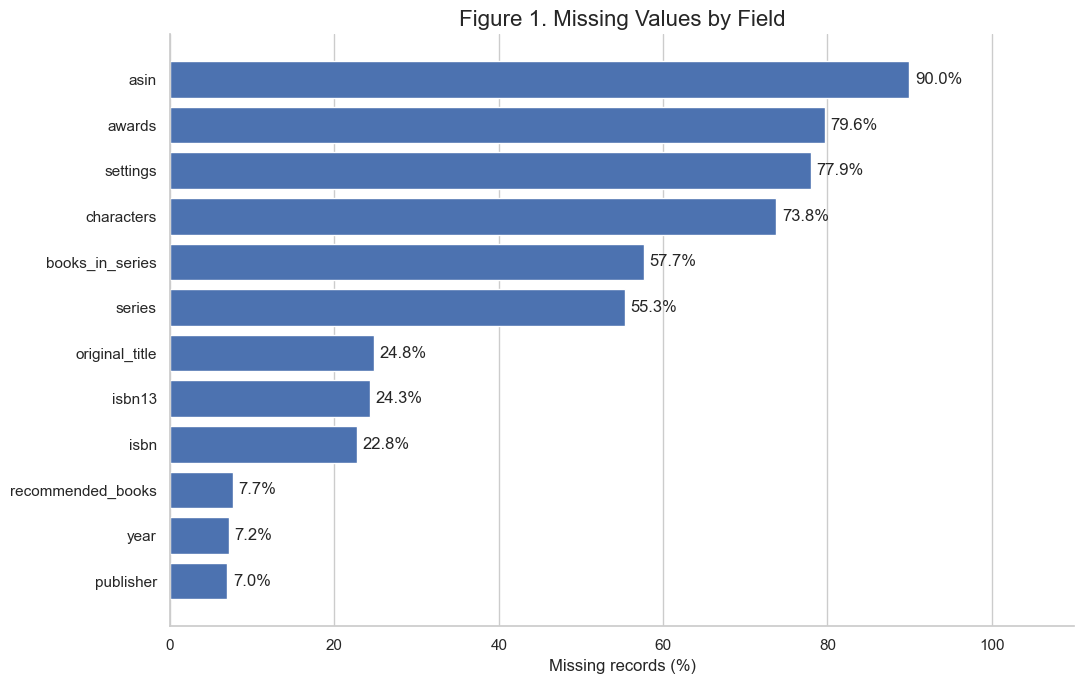

In [3]:
missing = (
    books.isna()
    .mean()
    .mul(100)
    .nlargest(12)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    missing.index,
    missing.values,
)

ax.bar_label(
    bars,
    fmt="%.1f%%",
    padding=4
)

ax.set_xlim(0, 110)
ax.set_title("Figure 1. Missing Values by Field")
ax.set_xlabel("Missing records (%)")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

Figure 1 shows the percentage of missing values in the twelve most incomplete fields before analysis filtering. This identifies which variables are available for reliable comparisons and which would require additional cleaning or a smaller analysis sample. Missing metadata should not automatically be interpreted as the absence of a characteristic.

### Figure 2. Bar Chart

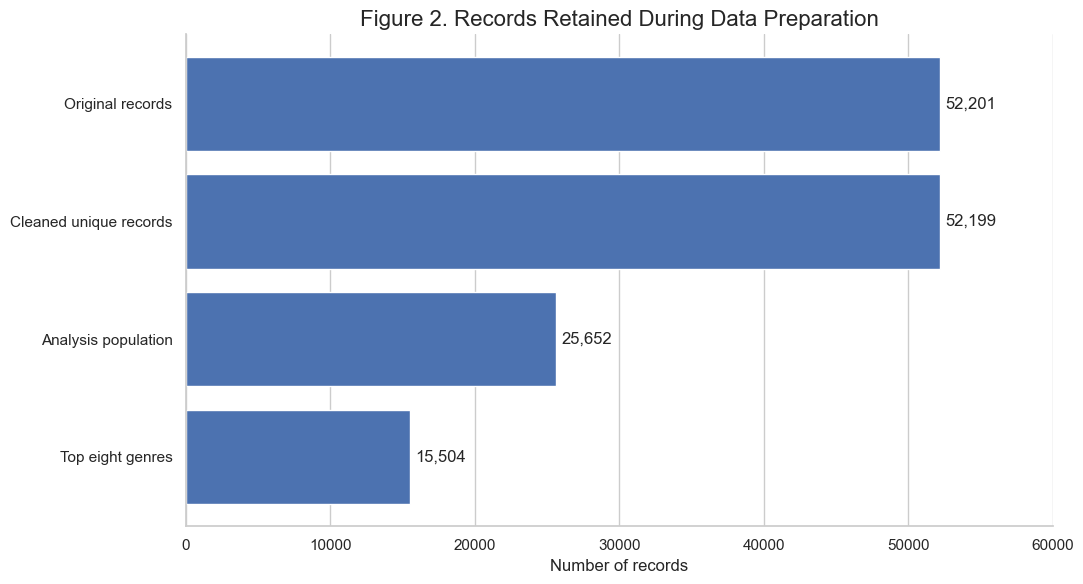

In [4]:
stage_counts = pd.Series({
    "Original records": len(books_raw),
    "Cleaned unique records": len(books),
    "Analysis population": len(plotdata),
    "Top eight genres": len(genredata)
})

fig, ax = plt.subplots()

bars = ax.barh(
    stage_counts.index[::-1],
    stage_counts.values[::-1],
)

ax.bar_label(
    bars,
    labels=[f"{v:,}" for v in stage_counts.values[::-1]],
    padding=4
)

ax.set_xlim(0, stage_counts.max() * 1.15)
ax.set_title("Figure 2. Records Retained During Data Preparation")
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

Figure 2 documents how many records remain after cleaning and filtering. Showing these counts makes the analysis reproducible and clarifies that the final charts represent a selected population. The top-eight-genre subset is used for readable genre comparisons, while other charts use the full analysis population.

### Figure 3. Histogram

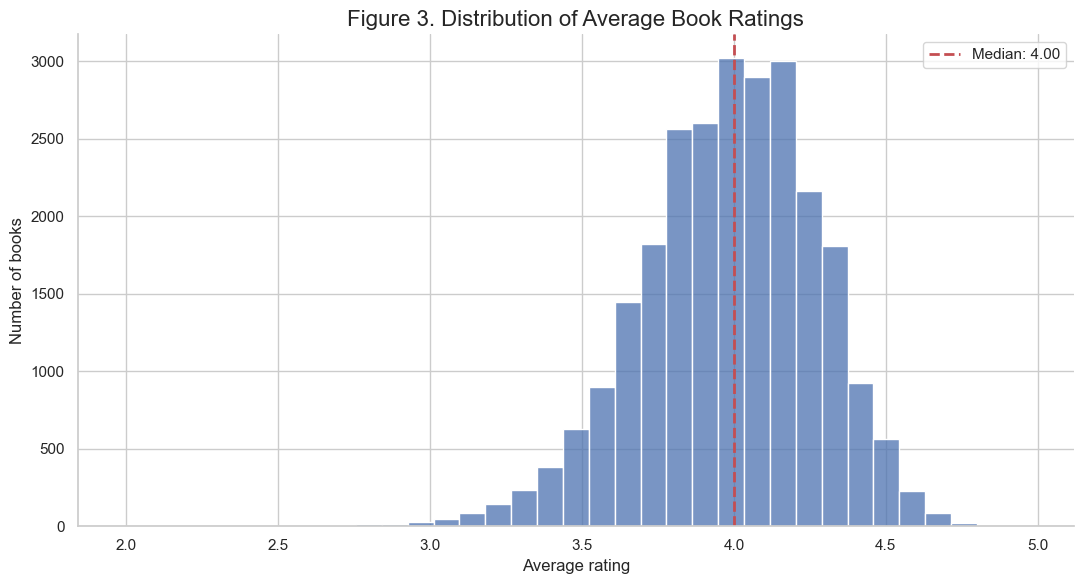

In [5]:
fig, ax = plt.subplots()

sns.histplot(
    data=plotdata,
    x="average_rating",
    bins=35,
    ax=ax
)

median_rating = plotdata["average_rating"].median()

ax.axvline(
    median_rating,
    color="#C44E52",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_rating:.2f}"
)

ax.set_title("Figure 3. Distribution of Average Book Ratings")
ax.set_xlabel("Average rating")
ax.set_ylabel("Number of books")
ax.legend()

plt.tight_layout()
plt.show()

Figure 3 shows how average ratings are distributed across the selected books. The dashed line marks the median, providing a reference for a typical book in this sample. The shape of the distribution helps identify whether ratings are concentrated within a narrow range or spread across the scale.

### Figure 4. Histogram

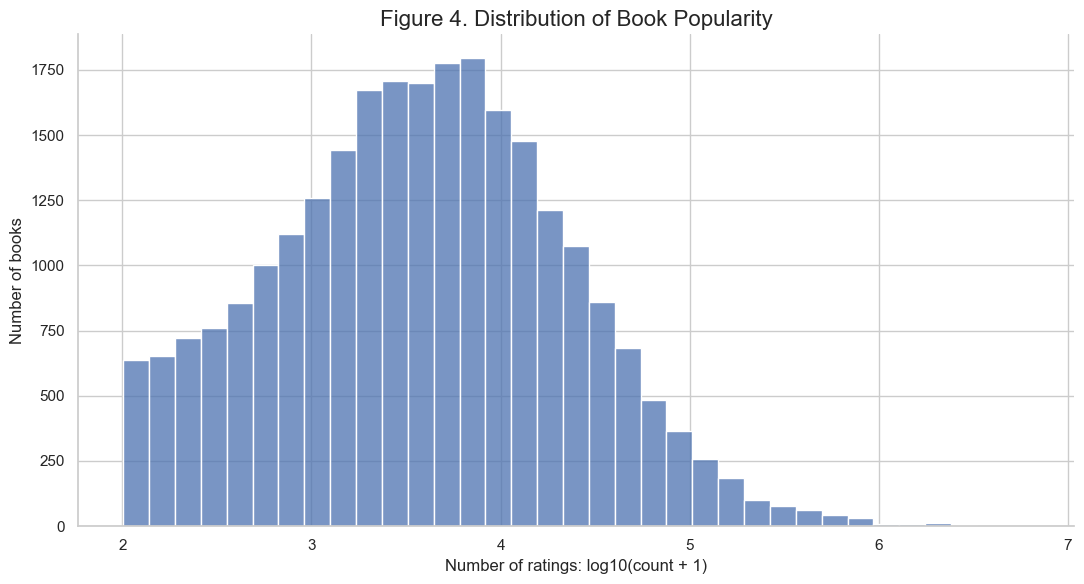

In [6]:
fig, ax = plt.subplots()

sns.histplot(
    data=plotdata,
    x="log_ratings",
    bins=35,
    ax=ax
)

ax.set_title("Figure 4. Distribution of Book Popularity")
ax.set_xlabel("Number of ratings: log10(count + 1)")
ax.set_ylabel("Number of books")

plt.tight_layout()
plt.show()

Figure 4 examines popularity using the number of ratings as a proxy. The logarithmic transformation makes books with very different rating counts visible on the same axis. Values near 2, 3, and 4 represent approximately 100, 1,000, and 10,000 ratings, respectively.

### Figure 5. Histogram

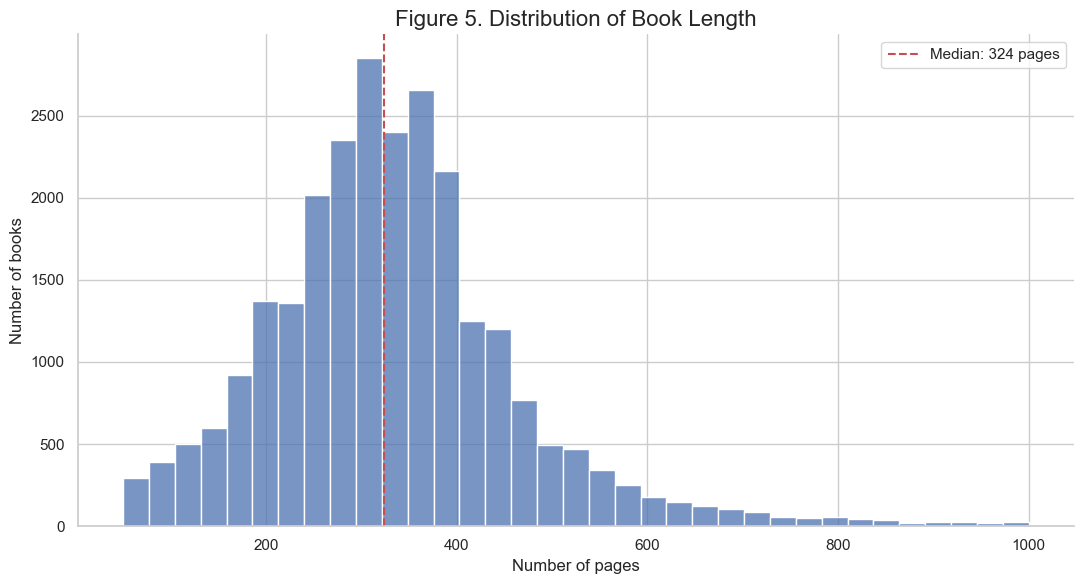

In [7]:
fig, ax = plt.subplots()

sns.histplot(
    data=plotdata,
    x="number_of_pages",
    bins=35,
    ax=ax
)

median_pages = plotdata["number_of_pages"].median()

ax.axvline(
    median_pages,
    color="#C44E52",
    linestyle="--",
    label=f"Median: {median_pages:,.0f} pages"
)

ax.set_title("Figure 5. Distribution of Book Length")
ax.set_xlabel("Number of pages")
ax.set_ylabel("Number of books")
ax.legend()

plt.tight_layout()
plt.show()

Figure 5 shows the distribution of book lengths within the 50–1,000-page analysis range. The median provides a useful reference for comparing shorter and longer books. Because page limits were applied during preparation, the chart does not describe the full range of lengths in the original dataset.

### Figure 6. Bar Chart

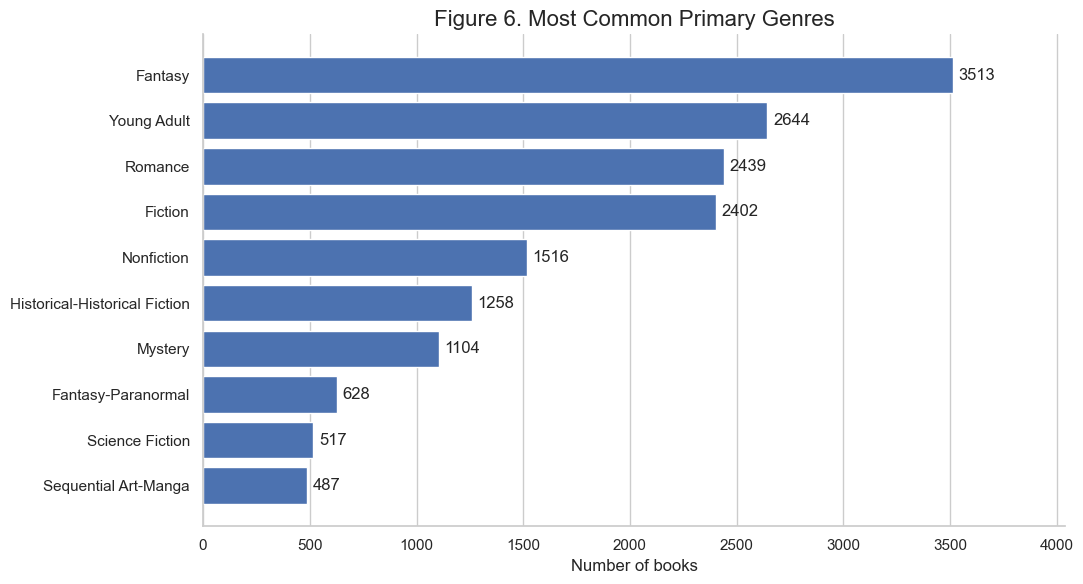

In [8]:
genre_counts = (
    plotdata["genre"]
    .value_counts()
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots()

bars = ax.barh(
    genre_counts.index,
    genre_counts.values,
    color="#4C72B0"
)

ax.bar_label(
    bars,
    fmt="%.0f",
    padding=4
)

ax.set_xlim(0, genre_counts.max() * 1.15)
ax.set_title("Figure 6. Most Common Primary Genres")
ax.set_xlabel("Number of books")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

Figure 6 compares the number of books assigned to each of the ten most common primary genres. It describes the composition of the analysis sample rather than market share or reader demand. A book may have several genre labels, but this chart counts it only under its first listed genre.

### Figure 7. Box Plot

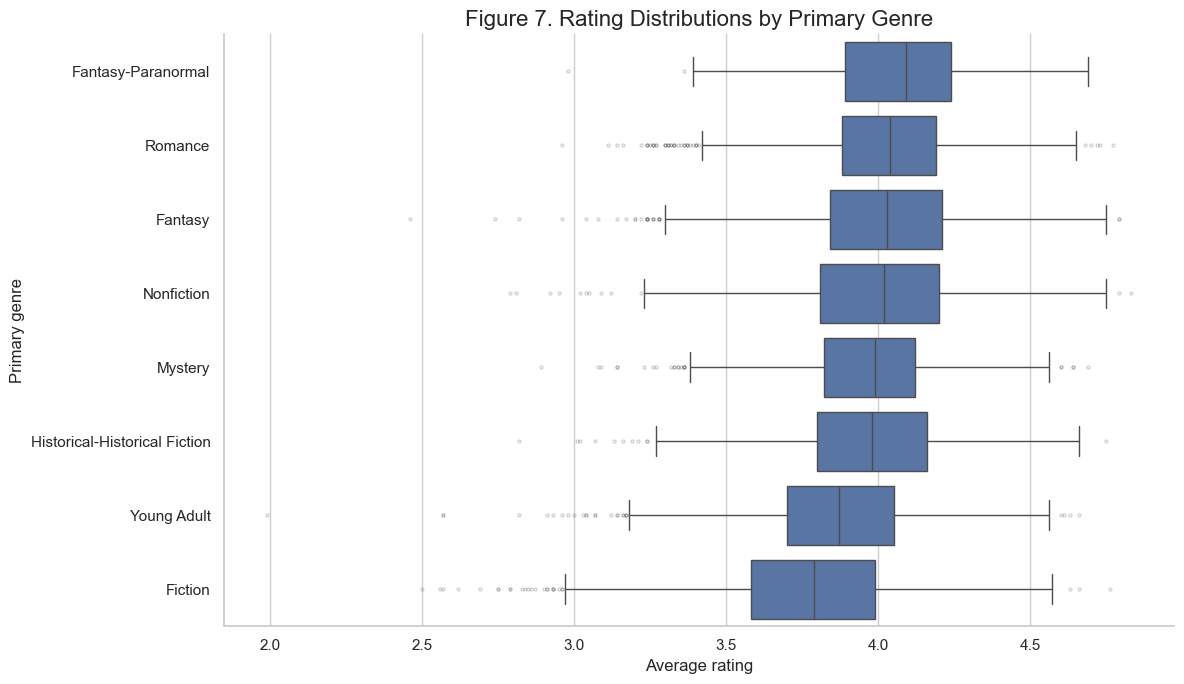

In [9]:
genre_order = (
    genredata.groupby("genre")["average_rating"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=genredata,
    x="average_rating",
    y="genre",
    order=genre_order,
    flierprops={
        "markersize": 2,
        "alpha": 0.25
    },
    ax=ax
)

ax.set_title("Figure 7. Rating Distributions by Primary Genre")
ax.set_xlabel("Average rating")
ax.set_ylabel("Primary genre")

plt.tight_layout()
plt.show()

Figure 7 compares the median, middle half, and outlying average ratings for the eight largest genres. Overlapping boxes indicate that genre differences may be small relative to variation among individual books. Differences in reader populations and book selection also affect these comparisons.

### Figure 8. Violin Plot

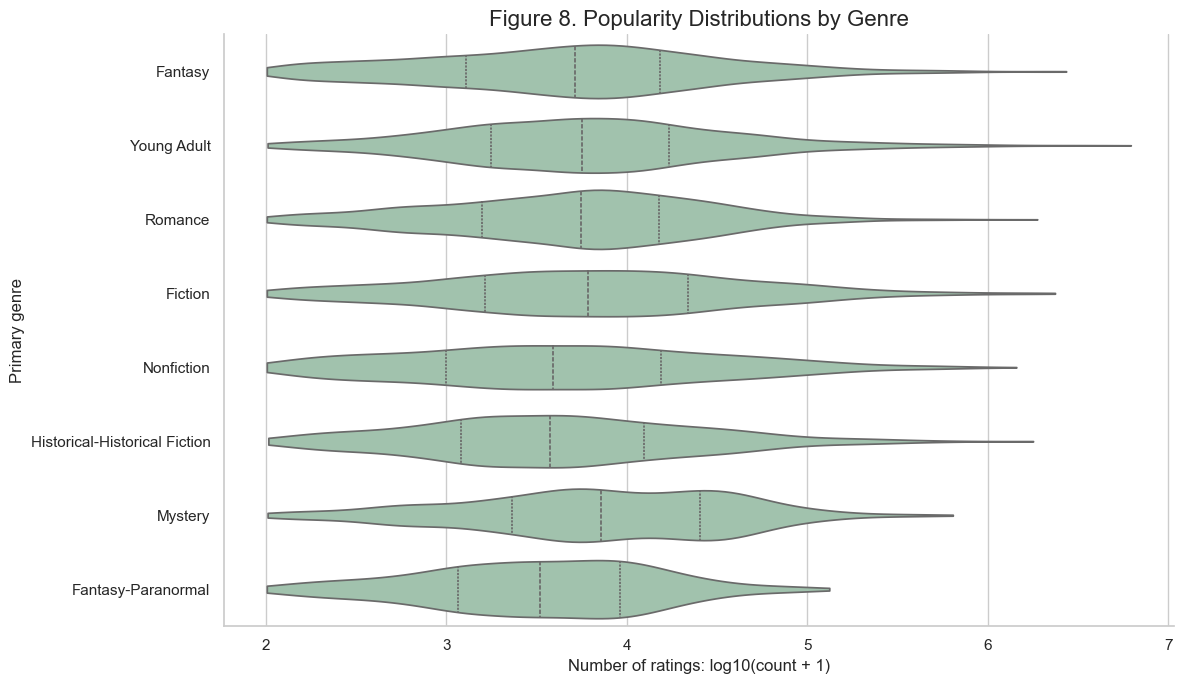

In [10]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.violinplot(
    data=genredata,
    x="log_ratings",
    y="genre",
    order=top_genres,
    inner="quartile",
    cut=0,
    color="#9BC7AC",
    ax=ax
)

ax.set_title("Figure 8. Popularity Distributions by Genre")
ax.set_xlabel("Number of ratings: log10(count + 1)")
ax.set_ylabel("Primary genre")

plt.tight_layout()
plt.show()

Figure 8 compares the distribution of rating counts across genres. Wider sections of each violin indicate concentrations of books at particular popularity levels, while the internal lines mark quartiles. The chart shows both typical popularity and variation, which a single genre average would conceal.

### Figure 9. Scatterplot Matrix

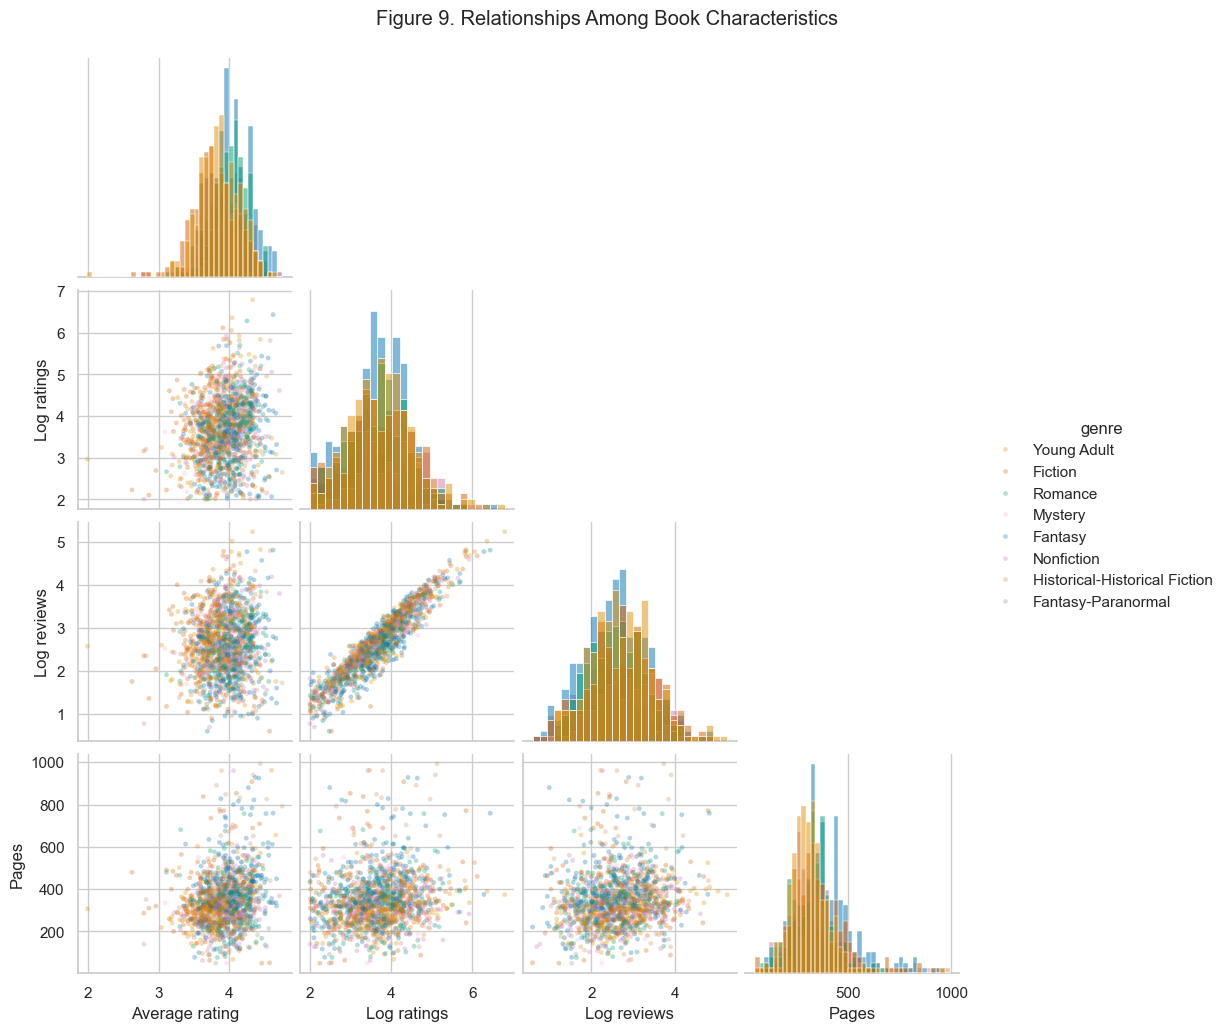

In [11]:
matrix_columns = {
    "average_rating": "Average rating",
    "log_ratings": "Log ratings",
    "log_reviews": "Log reviews",
    "number_of_pages": "Pages"
}

matrixdata = (
    scatterdata[
        list(matrix_columns) + ["genre"]
    ]
    .rename(columns=matrix_columns)
)

g = sns.pairplot(
    matrixdata,
    hue="genre",
    palette=palette,
    diag_kind="hist",
    corner=True,
    plot_kws={
        "alpha": 0.3,
        "s": 12,
        "edgecolor": "none"
    }
)

g.fig.suptitle(
    "Figure 9. Relationships Among Book Characteristics",
    y=1.03
)

plt.show()

Figure 9 combines pairwise comparisons of average rating, popularity, written reviews, and book length. It is useful for identifying potential relationships, clusters, and unusual observations before conducting more focused analysis. A reproducible sample limits overplotting, and logarithmic counts make engagement measures easier to compare.

### Figure 10. Correlation Heatmap

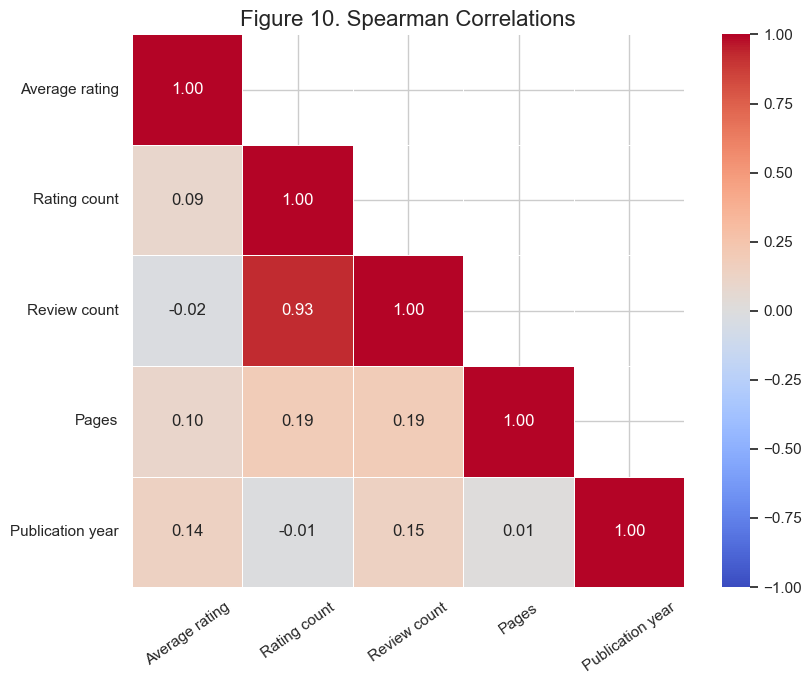

In [12]:
correlation_data = plotdata[[
    "average_rating",
    "rating_count",
    "review_count",
    "number_of_pages",
    "year"
]].rename(columns={
    "average_rating": "Average rating",
    "rating_count": "Rating count",
    "review_count": "Review count",
    "number_of_pages": "Pages",
    "year": "Publication year"
})

correlation = correlation_data.corr(
    method="spearman"
)

mask = np.triu(
    np.ones_like(correlation, dtype=bool),
    k=1
)

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Figure 10. Spearman Correlations")
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

Figure 10 summarizes ranked associations between the numerical variables. Spearman correlation is useful here because engagement counts are skewed and relationships may not be linear. Values near zero indicate weak monotonic associations, while values near either extreme indicate stronger associations; none establish causation.

### Figure 11. Hexbin Plot

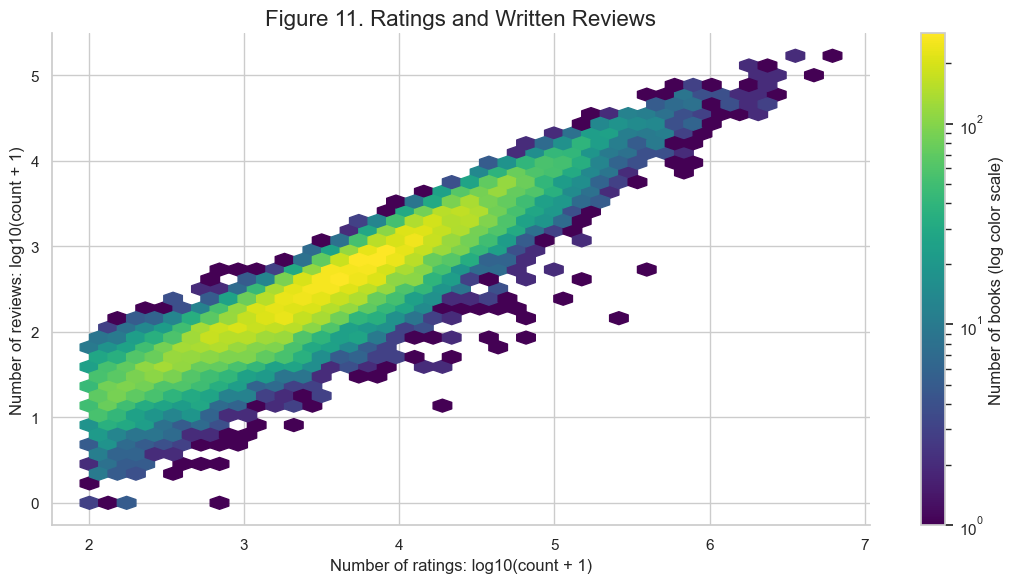

In [13]:
fig, ax = plt.subplots()

density = ax.hexbin(
    plotdata["log_ratings"],
    plotdata["log_reviews"],
    gridsize=40,
    mincnt=1,
    bins="log",
    cmap="viridis"
)

fig.colorbar(
    density,
    ax=ax,
    label="Number of books (log color scale)"
)

ax.set_title("Figure 11. Ratings and Written Reviews")
ax.set_xlabel("Number of ratings: log10(count + 1)")
ax.set_ylabel("Number of reviews: log10(count + 1)")

plt.tight_layout()
plt.show()

Figure 11 examines the relationship between ratings and written reviews using hexagonal bins. Each hexagon represents a region of the plot, and its color indicates how many books fall there. This approach reveals dense patterns more clearly than plotting every book as an overlapping point.

### Figure 12. Hexbin Plot

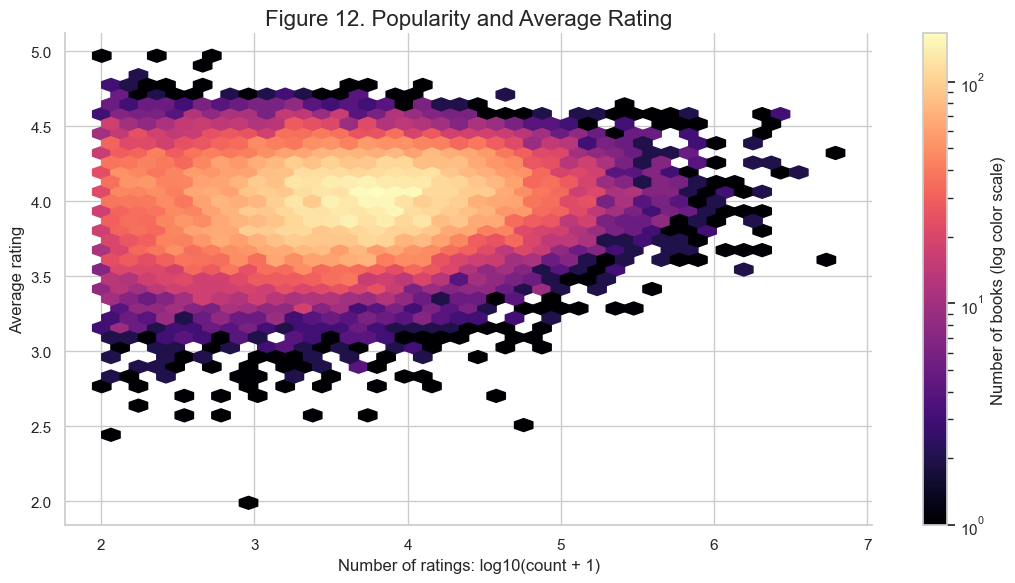

In [14]:
fig, ax = plt.subplots()

density = ax.hexbin(
    plotdata["log_ratings"],
    plotdata["average_rating"],
    gridsize=40,
    mincnt=1,
    bins="log",
    cmap="magma"
)

fig.colorbar(
    density,
    ax=ax,
    label="Number of books (log color scale)"
)

ax.set_title("Figure 12. Popularity and Average Rating")
ax.set_xlabel("Number of ratings: log10(count + 1)")
ax.set_ylabel("Average rating")

plt.tight_layout()
plt.show()

Figure 12 explores whether highly rated books also tend to attract more ratings. The density view shows where most books lie and whether rating variability changes with popularity. Rating count measures engagement, whereas average rating measures the evaluations submitted by participating readers.

### Figure 13. Bubble Chart

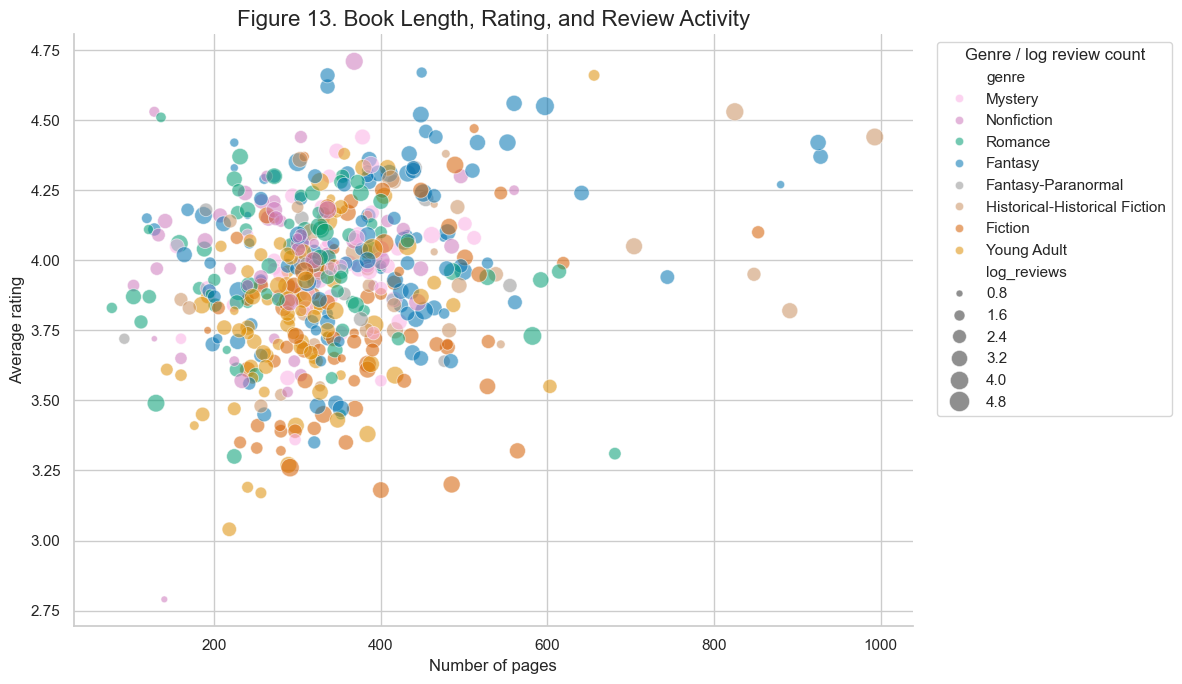

In [15]:
bubbledata = scatterdata.sample(
    n=min(500, len(scatterdata)),
    random_state=445
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
    data=bubbledata,
    x="number_of_pages",
    y="average_rating",
    hue="genre",
    palette=palette,
    size="log_reviews",
    sizes=(20, 220),
    alpha=0.55,
    ax=ax
)

ax.set_title("Figure 13. Book Length, Rating, and Review Activity")
ax.set_xlabel("Number of pages")
ax.set_ylabel("Average rating")

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    title="Genre / log review count"
)

plt.tight_layout()
plt.show()

Figure 13 combines book length, average rating, genre, and review activity in one view. Bubble size represents the logarithm of review count, so larger bubbles indicate more written reviews without allowing extremely popular books to dominate the display. The chart supports exploration of whether length-related patterns differ across genres.

### Figure 14. Faceted Histogram

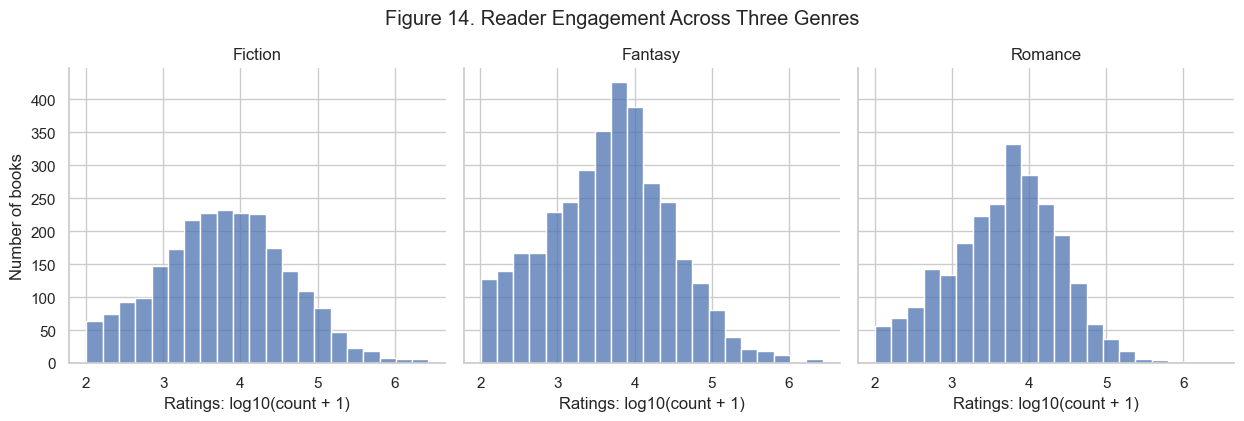

In [16]:
g = sns.FacetGrid(
    threegenredata,
    col="genre",
    col_order=three_genres,
    height=4,
    aspect=1.05,
    sharex=True,
    sharey=True
)

shared_bins = np.linspace(
    threegenredata["log_ratings"].min(),
    threegenredata["log_ratings"].max(),
    22
)

g.map_dataframe(
    sns.histplot,
    x="log_ratings",
    bins=shared_bins,
)

g.set_axis_labels(
    "Ratings: log10(count + 1)",
    "Number of books"
)

g.set_titles("{col_name}")

g.fig.suptitle(
    "Figure 14. Reader Engagement Across Three Genres",
    y=1.05
)

plt.show()

Figure 14 displays popularity distributions separately for Fiction, Fantasy, and Romance. Shared axes and bin boundaries allow direct comparison across the panels. The heights represent book counts, so differences reflect both distribution shape and the number of books available in each genre.

### Figure 15. Line Chart

In [17]:
yearly = (
    threegenredata
    .groupby(["year", "genre"])
    .agg(
        median_rating=("average_rating", "median"),
        book_count=("title", "size")
    )
    .reset_index()
)

yearly = yearly.loc[
    yearly["book_count"] >= 30
]

fig = px.line(
    yearly,
    x="year",
    y="median_rating",
    color="genre",
    markers=True,
    hover_data={"book_count": True},
    labels={
        "year": "Listed Publication Year",
        "median_rating": "Median Average Rating",
        "genre": "Primary Genre",
        "book_count": "Number of Books"
    },
    title="Figure 15. Ratings by Publication-Year Cohort",
    template="plotly_white"
)

fig.update_xaxes(dtick=2)
fig.show()

Figure 15 compares median ratings for books grouped by listed publication year and genre. Only groups containing at least thirty books are displayed. This is a comparison of publication cohorts using the ratings available in the dataset, rather than a record of how ratings changed historically.

### Figure 16. Stacked Bar Chart

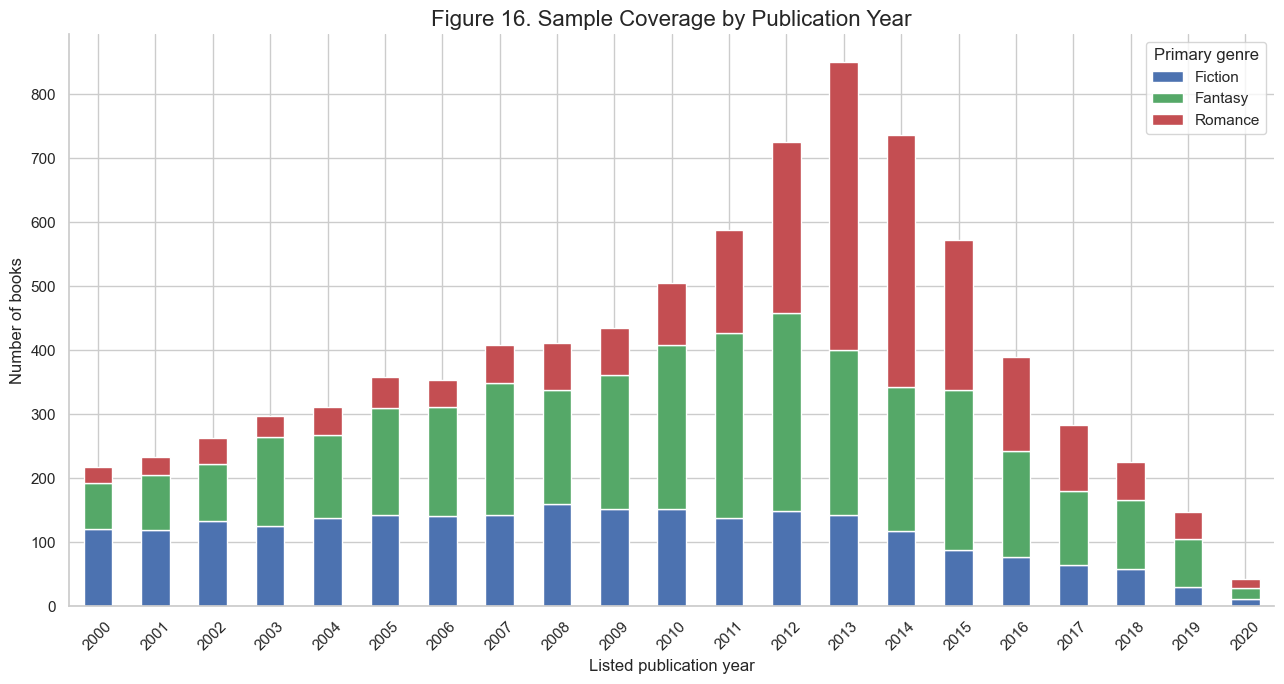

In [18]:
annual_counts = (
    threegenredata
    .groupby(["year", "genre"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=three_genres, fill_value=0)
)

ax = annual_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 7),
    color=["#4C72B0", "#55A868", "#C44E52"]
)

ax.set_xticklabels(
    [str(int(year)) for year in annual_counts.index],
    rotation=45
)

ax.set_title("Figure 16. Sample Coverage by Publication Year")
ax.set_xlabel("Listed publication year")
ax.set_ylabel("Number of books")
ax.legend(title="Primary genre")

plt.tight_layout()
plt.show()

Figure 16 shows how the analysis sample is distributed across publication years for the three selected genres. It provides context for the preceding rating trends because years with fewer books have less support. These counts describe dataset coverage, not the total number of books published worldwide.

### Figure 17. Heatmap

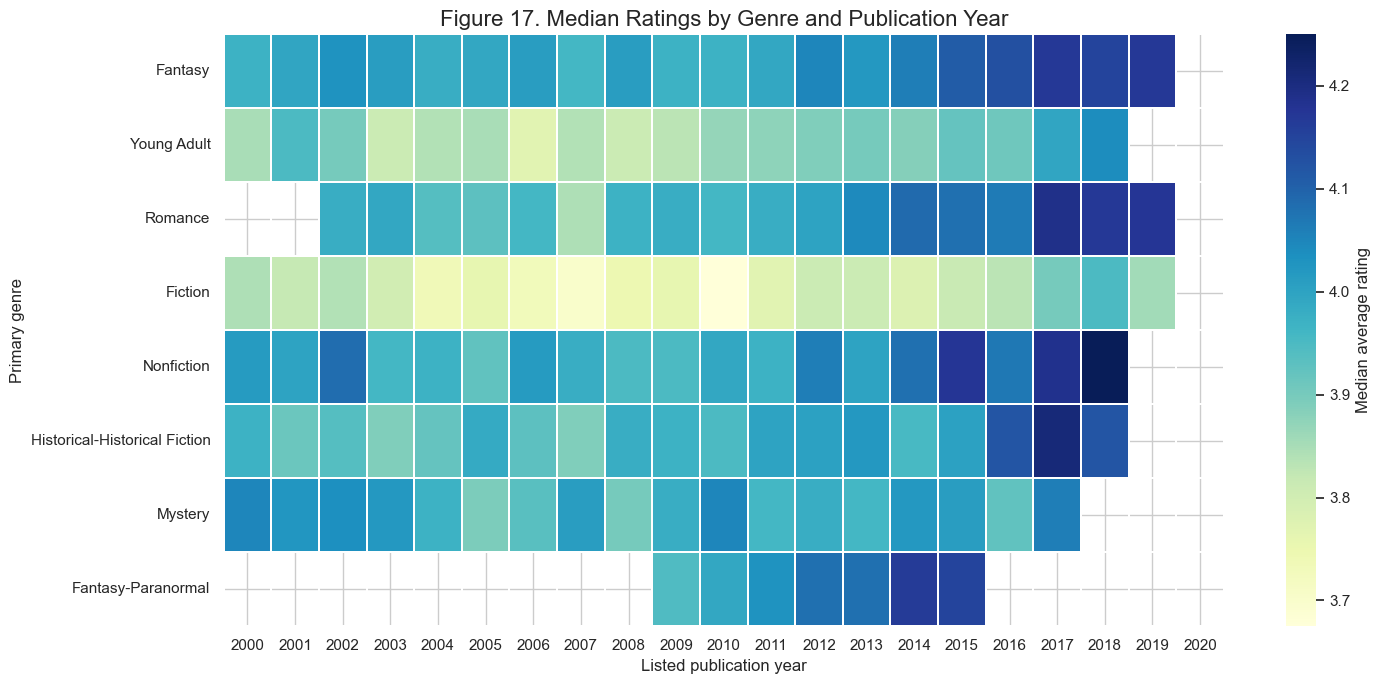

In [19]:
cohort_summary = (
    genredata
    .groupby(["genre", "year"])
    .agg(
        median_rating=("average_rating", "median"),
        book_count=("title", "size")
    )
    .reset_index()
)

cohort_summary.loc[
    cohort_summary["book_count"] < 30,
    "median_rating"
] = np.nan

cohort_matrix = (
    cohort_summary
    .pivot(
        index="genre",
        columns="year",
        values="median_rating"
    )
    .reindex(top_genres)
)

cohort_matrix.columns = (
    cohort_matrix.columns.astype(int)
)

fig, ax = plt.subplots(figsize=(15, 7))

sns.heatmap(
    cohort_matrix,
    cmap="YlGnBu",
    linewidths=0.3,
    cbar_kws={"label": "Median average rating"},
    ax=ax
)

ax.set_title("Figure 17. Median Ratings by Genre and Publication Year")
ax.set_xlabel("Listed publication year")
ax.set_ylabel("Primary genre")

plt.tight_layout()
plt.show()

Figure 17 summarizes genre and publication-year differences in a compact matrix. Darker cells represent higher median ratings, while blank cells indicate missing groups or fewer than thirty books. The chart helps locate patterns that may be difficult to distinguish when many genre lines overlap.

### Figure 18. Box Plot

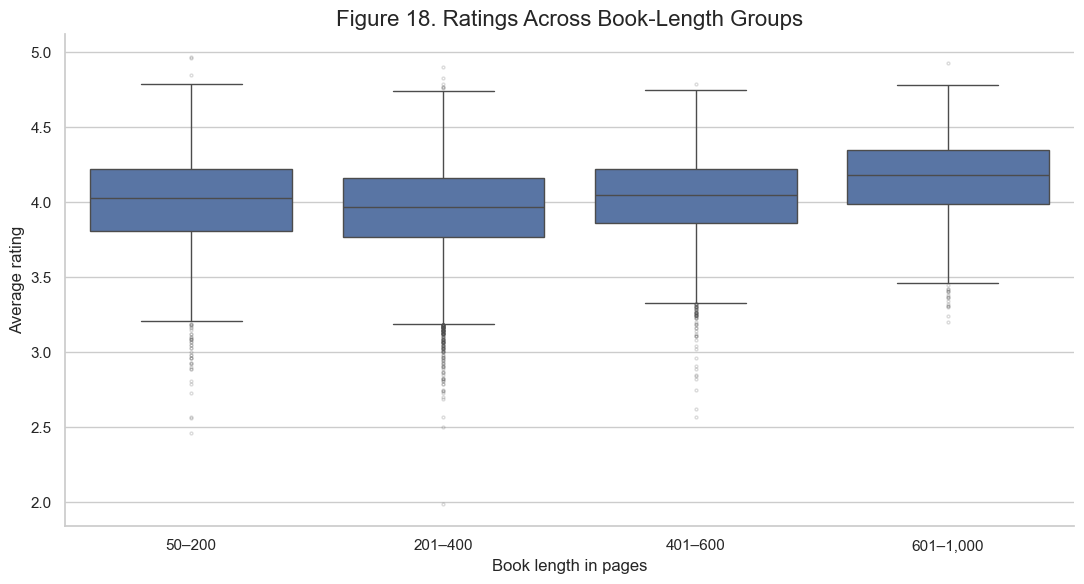

In [20]:
fig, ax = plt.subplots()

sns.boxplot(
    data=plotdata,
    x="length_group",
    y="average_rating",
    flierprops={
        "markersize": 2,
        "alpha": 0.2
    },
    ax=ax
)

ax.set_title("Figure 18. Ratings Across Book-Length Groups")
ax.set_xlabel("Book length in pages")
ax.set_ylabel("Average rating")

plt.tight_layout()
plt.show()

Figure 18 compares rating distributions across four page-length categories. Grouping length makes differences in medians and variability easier to inspect than in a dense scatterplot. Any differences are descriptive and may also reflect genre, readership, or other characteristics associated with book length.

### Figure 19. Box Plot

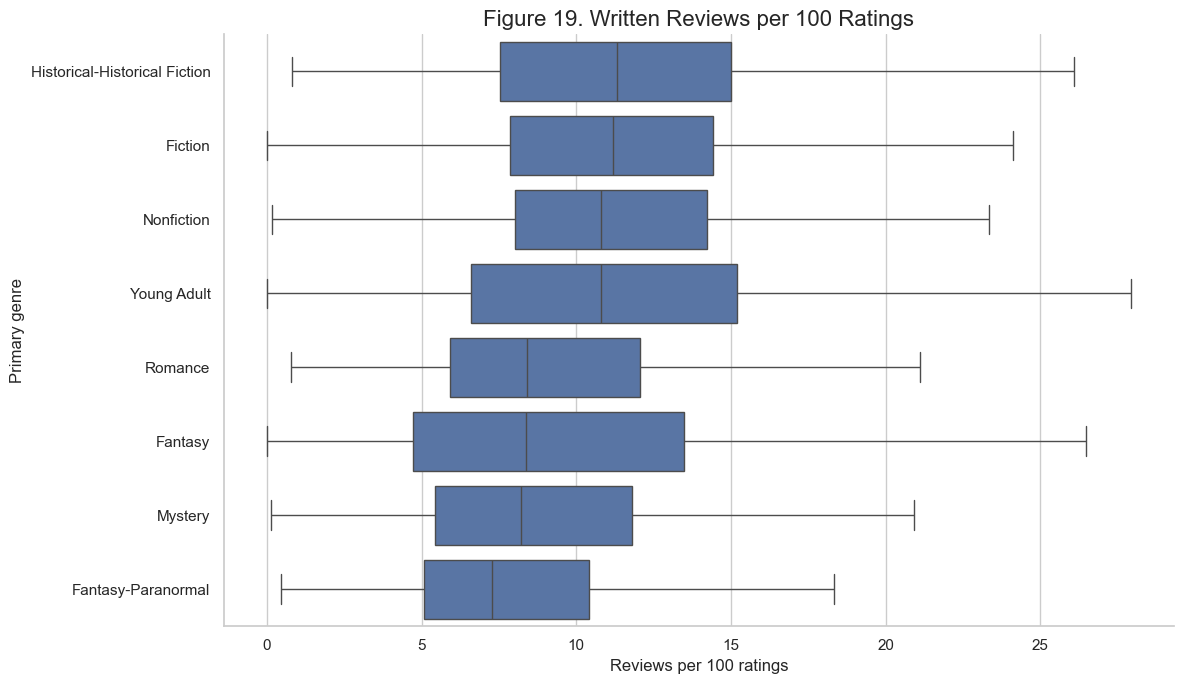

In [21]:
engagement_order = (
    genredata
    .groupby("genre")["reviews_per_100_ratings"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=genredata,
    x="reviews_per_100_ratings",
    y="genre",
    order=engagement_order,
    showfliers=False,
    ax=ax
)

ax.set_title("Figure 19. Written Reviews per 100 Ratings")
ax.set_xlabel("Reviews per 100 ratings")
ax.set_ylabel("Primary genre")

plt.tight_layout()
plt.show()

Figure 19 compares written-review activity relative to rating count. This ratio helps distinguish the volume of engagement from the tendency to submit written reviews. Outlier markers are hidden for readability, but their values remain part of the boxplot calculations; the ratio is not a verified individual-user conversion rate.

### Figure 20. Stacked Bar Chart

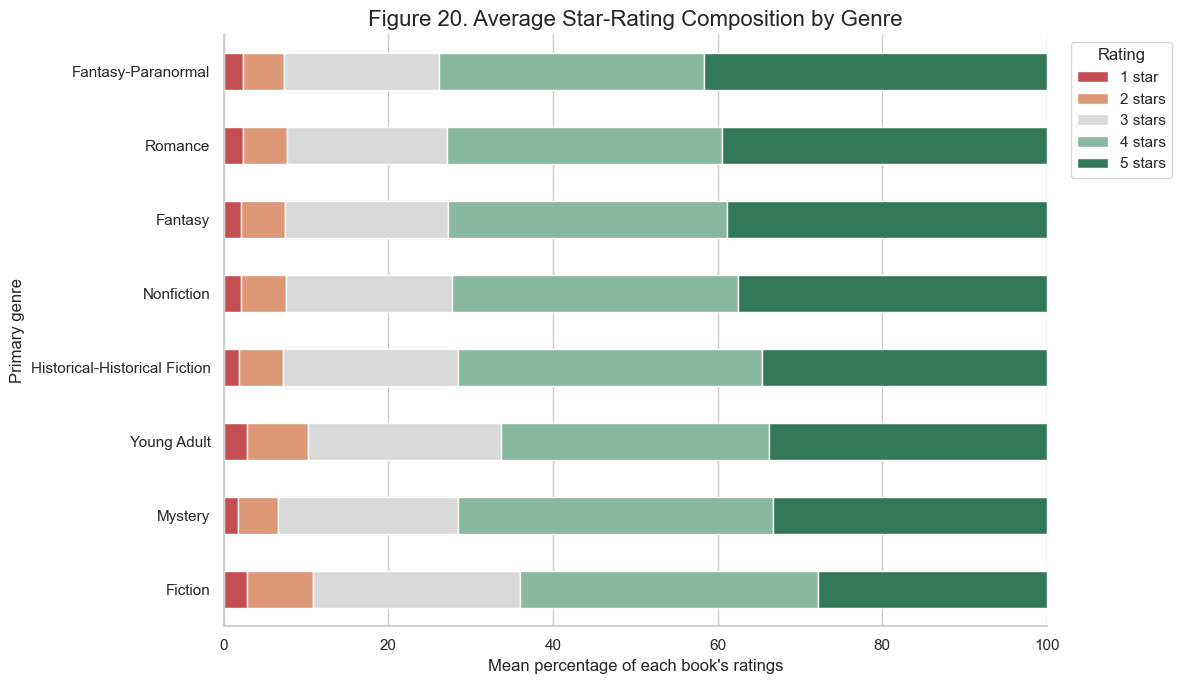

In [22]:
composition = (
    stardata
    .groupby("genre")[star_share_columns]
    .mean()
)

composition = composition.loc[
    composition["five_star_share"]
    .sort_values()
    .index
]

composition.columns = [
    "1 star",
    "2 stars",
    "3 stars",
    "4 stars",
    "5 stars"
]

ax = composition.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    color=[
        "#C44E52",
        "#DD9977",
        "#D9D9D9",
        "#88B8A0",
        "#34785A"
    ]
)

ax.set_xlim(0, 100)
ax.set_title("Figure 20. Average Star-Rating Composition by Genre")
ax.set_xlabel("Mean percentage of each book's ratings")
ax.set_ylabel("Primary genre")

ax.legend(
    title="Rating",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

Figure 20 compares the average proportion of one- through five-star ratings in each genre. Percentages are calculated separately for every book and then averaged, giving each book equal weight. This reveals rating composition that can be hidden when books are summarized only by their average scores.

### Figure 21. Waterfall Chart

In [23]:
star_totals = stardata[star_columns].sum()

star_labels = [
    "1 star",
    "2 stars",
    "3 stars",
    "4 stars",
    "5 stars"
]

fig = go.Figure(
    go.Waterfall(
        x=star_labels + ["Total"],
        y=star_totals.tolist() + [0],
        measure=["relative"] * 5 + ["total"],
        text=[
            f"{value / 1_000_000:.2f}M"
            for value in star_totals
        ] + [
            f"{star_totals.sum() / 1_000_000:.2f}M"
        ],
        textposition="outside",
        increasing={"marker": {"color": "#55A868"}},
        totals={"marker": {"color": "#4C72B0"}}
    )
)

fig.update_layout(
    title="Figure 21. Contributions to Total Star Ratings",
    xaxis_title="Star category",
    yaxis_title="Cumulative number of ratings",
    template="plotly_white",
    showlegend=False,
    height=600
)

fig.show()

Figure 21 shows how each star category contributes to the total ratings recorded for books with complete star data in the eight selected genres. Unlike Figure 20, this chart weights books according to their rating volume, so popular books have greater influence. The final bar represents the sum of the five star categories.

### Figure 22. Box Plot

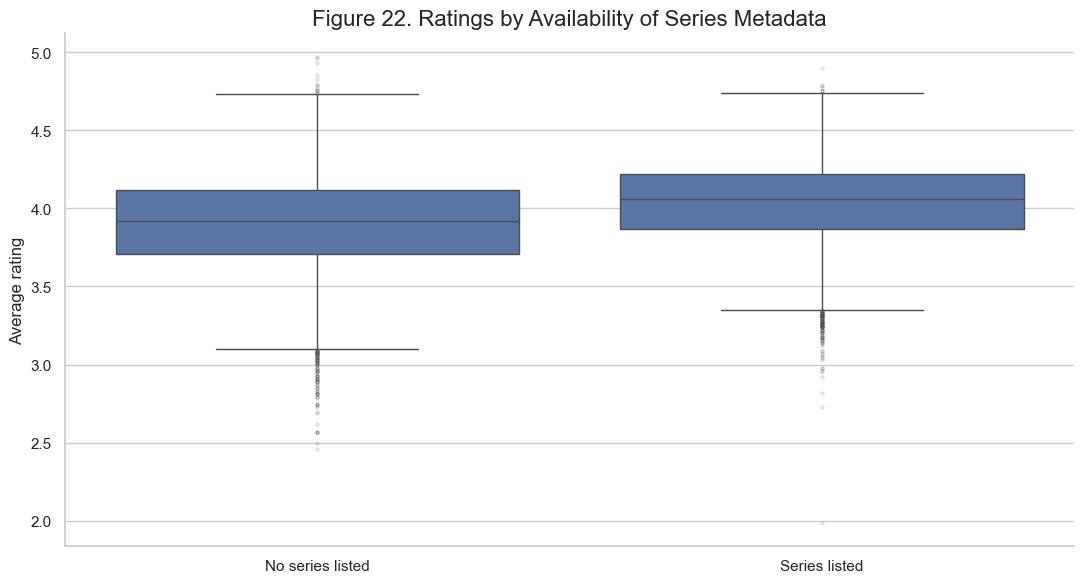

In [24]:
fig, ax = plt.subplots()

sns.boxplot(
    data=plotdata,
    x="series_status",
    y="average_rating",
    order=["No series listed", "Series listed"],
    flierprops={
        "markersize": 2,
        "alpha": 0.2
    },
    ax=ax
)

ax.set_title("Figure 22. Ratings by Availability of Series Metadata")
ax.set_xlabel("")
ax.set_ylabel("Average rating")

plt.tight_layout()
plt.show()

Figure 22 compares books with series information against books without listed series information. It explores whether the two groups have different rating distributions. Missing series metadata does not establish that a book is standalone, and any difference may also reflect genre or the readership of series boo

### Figure 23. Radar Chart

In [25]:
radar_books = (
    plotdata
    .nlargest(3, "rating_count")
    .copy()
)

radar_features = [
    "average_rating",
    "log_ratings",
    "log_reviews",
    "number_of_pages"
]

radar_labels = [
    "Average rating",
    "Popularity",
    "Written reviews",
    "Book length"
]

population_percentiles = plotdata[
    radar_features
].rank(pct=True).mul(100)

fig = go.Figure()

for index, row in radar_books.iterrows():
    values = (
        population_percentiles
        .loc[index, radar_features]
        .tolist()
    )

    fig.add_trace(
        go.Scatterpolar(
            r=values + [values[0]],
            theta=radar_labels + [radar_labels[0]],
            fill="toself",
            opacity=0.55,
            name=f"{row['title']} — {row['author']}"
        )
    )

fig.update_layout(
    title="Figure 23. Profiles of the Three Most-Rated Books",
    polar={
        "radialaxis": {
            "visible": True,
            "range": [0, 100],
            "ticksuffix": "%"
        }
    },
    legend_title_text="Book",
    template="plotly_white",
    height=700
)

fig.show()

Figure 23 compares the three most-rated books using percentile ranks within the entire analysis population. A value near 100 indicates that a book ranks highly on that measure relative to other selected books. These dimensions describe different characteristics, so a larger radar area should not be interpreted as a better overall book.

### Figure 24. 3D Scatterplot

In [26]:
three_d_sample = threegenredata.sample(
    n=min(4000, len(threegenredata)),
    random_state=445
)

fig = px.scatter_3d(
    three_d_sample,
    x="log_ratings",
    y="log_reviews",
    z="average_rating",
    color="genre",
    color_discrete_map={
        "Fiction": "#4C72B0",
        "Fantasy": "#55A868",
        "Romance": "#C44E52"
    },
    hover_name="title",
    hover_data={
        "author": True,
        "rating_count": ":,.0f",
        "review_count": ":,.0f",
        "number_of_pages": ":,.0f",
        "year": ":.0f",
        "log_ratings": False,
        "log_reviews": False
    },
    labels={
        "log_ratings": "Ratings: log10(count + 1)",
        "log_reviews": "Reviews: log10(count + 1)",
        "average_rating": "Average Rating",
        "genre": "Primary Genre",
        "author": "Author",
        "rating_count": "Number of Ratings",
        "review_count": "Number of Reviews",
        "number_of_pages": "Pages",
        "year": "Publication Year"
    },
    title="Figure 24. Popularity, Reviews, and Ratings in 3D",
    template="plotly_white",
    height=800
)

fig.update_traces(
    marker={
        "size": 3,
        "opacity": 0.55
    }
)

fig.update_layout(
    margin={
        "l": 0,
        "r": 0,
        "b": 0,
        "t": 60
    }
)

fig.show()

Figure 24 combines popularity, written-review volume, and average rating in an interactive three-dimensional view. Color distinguishes Fiction, Fantasy, and Romance, while hover information identifies individual books. Rotation helps explore clusters and unusual observations, although the two-dimensional charts remain easier for precise comparisons.